# XAS Static Good (Tunnel GMD)

Starts from `run{RUN_NO}_good_static_xas_tunnel.h5`. Functions live in `analysis/scripts/static_xas_good_xas.py`; this notebook mirrors `xas_static_good.ipynb` but sets `GMD_SOURCE = "tunnel"` so the old GMD/VLS workflow uses `/gmd_tunnel` and tunnel-derived corrected VLS/transmission.


In [12]:
# Cell 1: config only
from __future__ import annotations

import importlib
import os
import sys
import tempfile
from pathlib import Path

mpl_cache = Path(tempfile.gettempdir()) / "glycine26-matplotlib-cache"
mpl_cache.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(mpl_cache))

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 160})


def find_repo_root(start: Path) -> Path:
    for parent in (start.resolve(), *start.resolve().parents):
        marker = parent / "analysis" / "scripts" / "static_xas_good_xas.py"
        if marker.exists():
            return parent
    raise RuntimeError("Could not find repo root from notebook path.")


REPO_ROOT = find_repo_root(Path.cwd())
SCRIPTS_DIR = REPO_ROOT / "analysis" / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import config as path_config
import static_xas_good_xas as gx
gx = importlib.reload(gx)


RUN_NO = 58794
INPUT_H5 = Path(path_config.COMBINED_DIR).parent / "xas_static" / f"run{RUN_NO}_good_static_xas_tunnel.h5"

# XAS range follows the bootstrap notebook; unit conversion is set separately below.
XAS_ANALYSIS_WINDOW_EV = (271.0, 282.0)

# Signal correction and reference-window VLS/uJ unit scaling.
CORRECTION_MODE = "per_axis_intercept"  # "none" or "per_axis_intercept"
UNIT_SCALE_AXIS = "converted"
UNIT_REFERENCE_WINDOW_EV = (271.0, 272.0)

# Binning choices.
PROXY_PIXEL_BIN_WIDTH = 1
NOMINAL_GROUP_DECIMALS = 3
GMD_EDGES = np.arange(1, 11, 1)
GMD_MIN_THRESHOLD = None
GMD_MAX_THRESHOLD = 10.0
GMD_SOURCE = "tunnel"  # "hall" or "tunnel"

# Bootstrap uncertainty for plotted error bars.
N_BOOTSTRAP = 500
BOOTSTRAP_SEED = 123
BOOTSTRAP_MIN_SHOTS_PER_BIN = 100
BOOTSTRAP_BATCH = 50

CONFIG = gx.GoodXASConfig(
    input_h5=INPUT_H5,
    energy_window_ev=XAS_ANALYSIS_WINDOW_EV,
    unit_scale_axis=UNIT_SCALE_AXIS,
    unit_reference_window_ev=UNIT_REFERENCE_WINDOW_EV,
    gmd_edges=tuple(GMD_EDGES),
    gmd_min_threshold=GMD_MIN_THRESHOLD,
    gmd_max_threshold=GMD_MAX_THRESHOLD,
    nominal_group_decimals=NOMINAL_GROUP_DECIMALS,
    proxy_pixel_bin_width=PROXY_PIXEL_BIN_WIDTH,
    correction_mode=CORRECTION_MODE,
    gmd_source=GMD_SOURCE,
)

INPUT_H5


PosixPath('/Users/hukaiyu/Desktop/PhD/FLASH Beamtime 202605/glycine26/11022188/processed/xas_static/run58794_good_static_xas_tunnel.h5')

In [13]:
result = gx.compute_good_xas(CONFIG)
bootstrap = gx.compute_bootstrap_errors(
    result,
    n_bootstrap=N_BOOTSTRAP,
    seed=BOOTSTRAP_SEED,
    min_shots_per_bin=BOOTSTRAP_MIN_SHOTS_PER_BIN,
    batch_size=BOOTSTRAP_BATCH,
)

gx.print_good_xas_summary(result)
gx.print_bootstrap_summary(bootstrap)

if result.converted.x.size <= result.nominal.x.size:
    print("WARNING: converted bins are not more numerous than nominal bins; check proxy-pixel grouping and input good H5.")


input H5            : /Users/hukaiyu/Desktop/PhD/FLASH Beamtime 202605/glycine26/11022188/processed/xas_static/run58794_good_static_xas_tunnel.h5
GMD source          : tunnel (gmd_tunnel)
stored good shots   : 897,048
accepted shots      : 732,902
nominal bins        : 29
converted bins      : 84
proxy pixel width   : 1
unit scale axis     : converted
unit scale window   : 271-272 eV
unit scale shots    : 52,684
VLS per uJ          : 15841.1
nominal shots/bin    : 1 / 3,008 / 9,303 min/median/max
converted shots/bin    : 1 / 1,046 / 3,157 min/median/max
bootstrap draws     : 500
bootstrap seed      : 123
bootstrap min shots : 100
nominal boot bins   : 248/261 finite
converted boot bins : 638/756 finite


1-2) uJ; mean 1.5: 86,494 shots
2-3) uJ; mean 2.5: 108,819 shots
3-4) uJ; mean 3.5: 104,907 shots
4-5) uJ; mean 4.5: 104,900 shots
5-6) uJ; mean 5.5: 91,376 shots
6-7) uJ; mean 6.5: 76,446 shots
7-8) uJ; mean 7.5: 65,997 shots
8-9) uJ; mean 8.5: 51,484 shots
9-10] uJ; mean 9.5: 42,479 shots


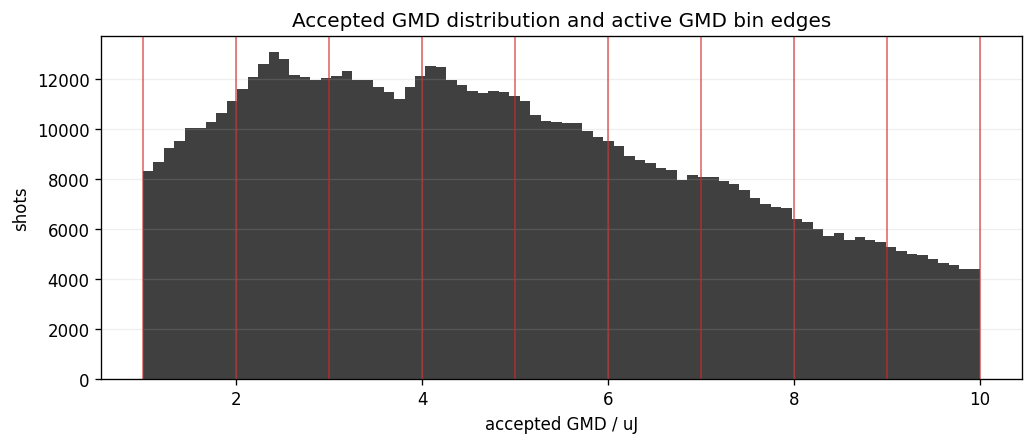

In [14]:
# Overall accepted-shot GMD audit
accepted_gmd = result.shots.gmd[result.keep_mask]
gmd_counts = []
for i, (lo, hi) in enumerate(zip(result.gmd_edges[:-1], result.gmd_edges[1:])):
    if i == len(result.gmd_edges) - 2:
        sel = (accepted_gmd >= lo) & (accepted_gmd <= hi)
    else:
        sel = (accepted_gmd >= lo) & (accepted_gmd < hi)
    gmd_counts.append(int(np.sum(sel)))

for label, count in zip(result.gmd_labels, gmd_counts):
    print(f"{label}: {count:,} shots")

fig, ax = plt.subplots(figsize=(8.5, 3.6), constrained_layout=True)
ax.hist(accepted_gmd[np.isfinite(accepted_gmd)], bins=80, color="0.25")
for edge in result.gmd_edges:
    ax.axvline(edge, color="tab:red", lw=0.9, alpha=0.75)
ax.set_xlabel("accepted GMD / uJ")
ax.set_ylabel("shots")
ax.set_title("Accepted GMD distribution and active GMD bin edges")
ax.grid(alpha=0.2)
plt.show()


In [15]:
# Cell 3: plotting parameters only
# Difference direction: Delta OD = OD[DIFF_BIN_B] - OD[DIFF_BIN_A]
DIFF_BIN_A = 1
DIFF_BIN_B = -1

SHOW_ERRORBARS = True

# Matplotlib can share x for copy-friendly aligned panels.
MATPLOTLIB_SHARE_X = True
MATPLOTLIB_XLIM = (271, 282)

# Plotly nominal/converted x-axes are independent for zooming.
PLOTLY_NOMINAL_XLIM = (271, 282)
PLOTLY_CONVERTED_XLIM = (271, 282)

NOMINAL_XAS_YLIM = (-0.1, 0.5)
CONVERTED_XAS_YLIM = (-0.1, 0.5)
NOMINAL_DELTA_YLIM = None
CONVERTED_DELTA_YLIM = None

SLOPE_XLIM = None
SLOPE_RAW_YLIM = None
SLOPE_SCALED_YLIM = None

gx.print_gmd_difference_summary(result, bin_a=DIFF_BIN_A, bin_b=DIFF_BIN_B)


Delta OD direction  : bin 8 - bin 1
bin A               : 2-3) uJ; mean 2.5
bin B               : 9-10] uJ; mean 9.5


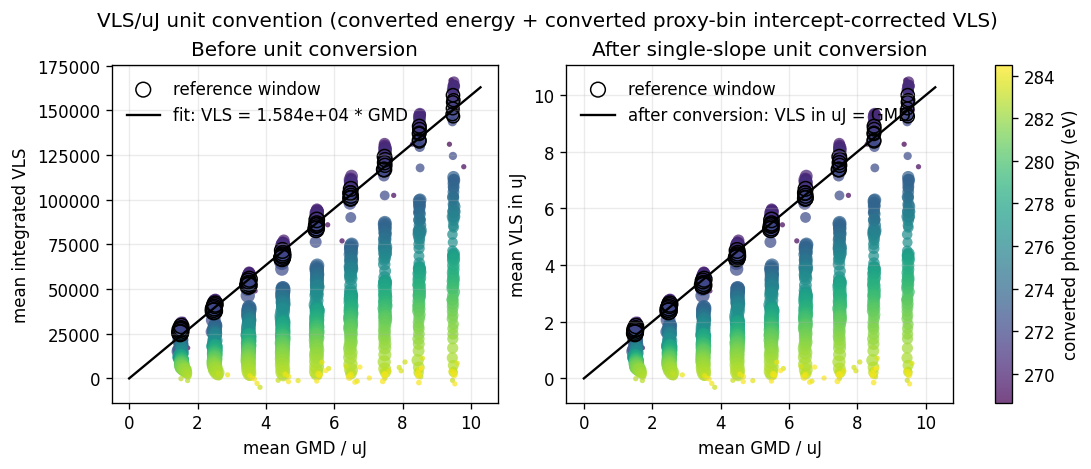

In [16]:
fig_slope, axes_slope = gx.plot_unit_scale_matplotlib(
    result,
    xlim=SLOPE_XLIM,
    raw_ylim=SLOPE_RAW_YLIM,
    scaled_ylim=SLOPE_SCALED_YLIM,
)
plt.show()


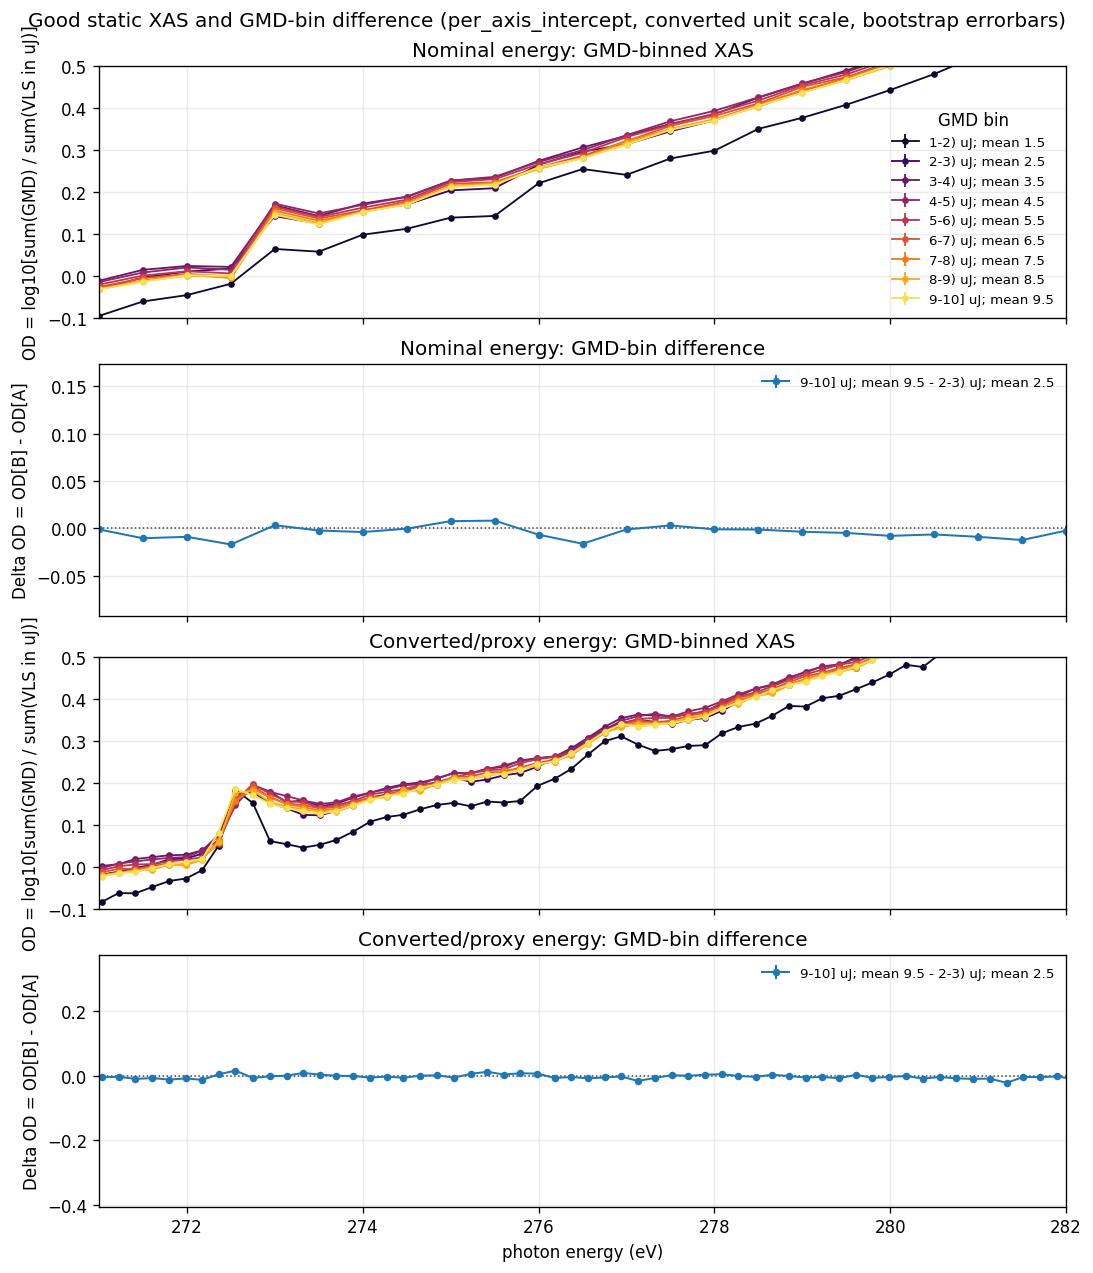

In [17]:
fig, axes = gx.plot_xas_with_gmd_difference_matplotlib(
    result,
    bootstrap=bootstrap,
    bin_a=DIFF_BIN_A,
    bin_b=DIFF_BIN_B,
    nominal_xlim=MATPLOTLIB_XLIM,
    converted_xlim=MATPLOTLIB_XLIM,
    xas_nominal_ylim=NOMINAL_XAS_YLIM,
    delta_nominal_ylim=NOMINAL_DELTA_YLIM,
    xas_converted_ylim=CONVERTED_XAS_YLIM,
    delta_converted_ylim=CONVERTED_DELTA_YLIM,
    share_xaxis=MATPLOTLIB_SHARE_X,
    show_errorbars=SHOW_ERRORBARS,
)
plt.show()


In [18]:
fig_plotly = gx.plot_xas_with_gmd_difference_plotly(
    result,
    bootstrap=bootstrap,
    bin_a=DIFF_BIN_A,
    bin_b=DIFF_BIN_B,
    nominal_xlim=PLOTLY_NOMINAL_XLIM,
    converted_xlim=PLOTLY_CONVERTED_XLIM,
    xas_nominal_ylim=NOMINAL_XAS_YLIM,
    delta_nominal_ylim=NOMINAL_DELTA_YLIM,
    xas_converted_ylim=CONVERTED_XAS_YLIM,
    delta_converted_ylim=CONVERTED_DELTA_YLIM,
    show_errorbars=SHOW_ERRORBARS,
)
fig_plotly


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'error_y': {'array': {'bdata': ('AAAAAAAA+H/xrS257CFcP7Vvi1lttF' ... '6px6w/AAAAAAAA+H8AAAAAAAD4fw=='),
                                    'dtype': 'f8'},
                          'type': 'data',
                          'visible': True},
              'legendgroup': '1-2) uJ; mean 1.5',
              'line': {'color': '#10092d', 'width': 1.4},
              'marker': {'color': '#10092d', 'size': 5},
              'mode': 'lines+markers',
              'name': '1-2) uJ; mean 1.5',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('AAAAAADgcEAAAAAAAOhwQAAAAAAA8H' ... 'AAsHFAAAAAAAC4cUAAAAAAAMBxQA=='),
                    'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': ('AAAAAAAA+H/y6giGo7u7v1SiloRBXL' ... 'QX8e0/AAAAAAAA+H8AAAAAAAD4fw=='),
                    'dtype': 'f8'},
              'yaxis': 'y'},
             {'error_y': {'array': {'bdata': ('AAAAAAAA+H9Zrpa/70RVPw/9pW64t1' ... 'dh544/plBKt4w6vj8AAAAAAAD4fw=='),
                                    'dtype': 'f8'},
                          'type': 'data',
                          'visible': True},
              'legendgroup': '2-3) uJ; mean 2.5',
              'line': {'color': '#3b0964', 'width': 1.4},
              'marker': {'color': '#3b0964', 'size': 5},
              'mode': 'lines+markers',
              'name': '2-3) uJ; mean 2.5',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('AAAAAADgcEAAAAAAAOhwQAAAAAAA8H' ... 'AAsHFAAAAAAAC4cUAAAAAAAMBxQA=='),
                    'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': ('AAAAAAAA+H/DMvablRylvzHg2QPVhp' ... 'Np3fA/llfx8fBm9j8AAAAAAAD4fw=='),
                    'dtype': 'f8'},
              'yaxis': 'y'},
             {'error_y': {'array': {'bdata': ('AAAAAAAA+H8N5cF8LvdUPzH/Cp5AmF' ... '3R0YM/6+ouKcGssD8AAAAAAAD4fw=='),
                                    'dtype': 'f8'},
                          'type': 'data',
                          'visible': True},
              'legendgroup': '3-4) uJ; mean 3.5',
              'line': {'color': '#67166e', 'width': 1.4},
              'marker': {'color': '#67166e', 'size': 5},
              'mode': 'lines+markers',
              'name': '3-4) uJ; mean 3.5',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('AAAAAADgcEAAAAAAAOhwQAAAAAAA8H' ... 'AAsHFAAAAAAAC4cUAAAAAAAMBxQA=='),
                    'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': ('AAAAAAAA+H8MYHPRPhiWv4gwrbTAZI' ... 'r4zPE/b2+z4VNV+D9YKUCXT1/8Pw=='),
                    'dtype': 'f8'},
              'yaxis': 'y'},
             {'error_y': {'array': {'bdata': ('AAAAAAAA+H8H8RQbhZlRP4N2ulrAxV' ... 'yAyn4/xo4xqaVbnz+5a7yoU//APw=='),
                                    'dtype': 'f8'},
                          'type': 'data',
                          'visible': True},
              'legendgroup': '4-5) uJ; mean 4.5',
              'line': {'color': '#922568', 'width': 1.4},
              'marker': {'color': '#922568', 'size': 5},
              'mode': 'lines+markers',
              'name': '4-5) uJ; mean 4.5',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('AAAAAADgcEAAAAAAAOhwQAAAAAAA8H' ... 'AAsHFAAAAAAAC4cUAAAAAAAMBxQA=='),
                    'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': ('AAAAAAAA+H80EVD6f7ibv3yKdrs8h4' ... 'dtVPI/66OrNe5M9z+GW1yjTvv6Pw=='),
                    'dtype': 'f8'},
              'yaxis': 'y'},
             {'error_y': {'array': {'bdata': ('AAAAAAAA+H9LT/U27/hRP1+zT3vt6E' ... 'dU6Ho/SmWCqgZTmT+nmmdkxPalPw=='),
                                    'dtype': 'f8'},
                          'type': 'data',
                          'visible': True},
              'legendgroup': '5-6) uJ; mean 5.5',
              'line': {'color': '#bc3754', 'width': 1.4},
              '

In [19]:
# Cell 7: feature-region comparison
FEATURE_COMPARISONS = [
    {
        "label": "converted 272.5 eV",
        "axis": "converted",
        "center_ev": 272.5,
        "half_width_ev": 0.05,
        "vls_mode": "axis_corrected",
    },
    {
        "label": "nominal 273.0 eV",
        "axis": "nominal",
        "center_ev": 273.0,
        "half_width_ev": 0.05,
        "vls_mode": "axis_corrected",
    },
]
FEATURE_MAX_SHOTS = None
FEATURE_RANDOM_SEED = 123
FEATURE_HIST_BINS = 80


In [20]:
features = [
    gx.feature_vls_stats(
        result,
        axis=item["axis"],
        center_ev=item["center_ev"],
        half_width_ev=item["half_width_ev"],
        vls_mode=item["vls_mode"],
        max_shots=FEATURE_MAX_SHOTS,
        seed=FEATURE_RANDOM_SEED,
    )
    for item in FEATURE_COMPARISONS
]
feature_labels = [item["label"] for item in FEATURE_COMPARISONS]
gx.feature_summary_comparison(features, labels=feature_labels)


,metric,converted 272.5 eV,nominal 273.0 eV
0,GMD mean ± std (uJ),3.297 ± 2.088,5.396 ± 2.368
1,VLS dataset,vls_intercept_corrected_converted,vls_intercept_corrected_nominal
2,axis,converted,nominal
3,converted energy mean ± std (eV),272.49 ± 0.028433,273.13 ± 0.3238
4,energy window (eV),272.4-272.6,272.9-273.1
5,"integrated VLS median [16,84]","2.835e+04 [1.328e+04, 6.393e+04]","5.492e+04 [2.841e+04, 9.067e+04]"
6,nominal energies,5 values: 271.5-273.5,1 value: 273
7,"peak SNR median [16,84]","47.1 [24, 103]","74 [29.9, 132]"
8,peak center mean ± std (pixel),569 ± 0.149,566 ± 1.7
9,"peak height median [16,84]","1528 [784.5, 3346]","2386 [992, 4229]"


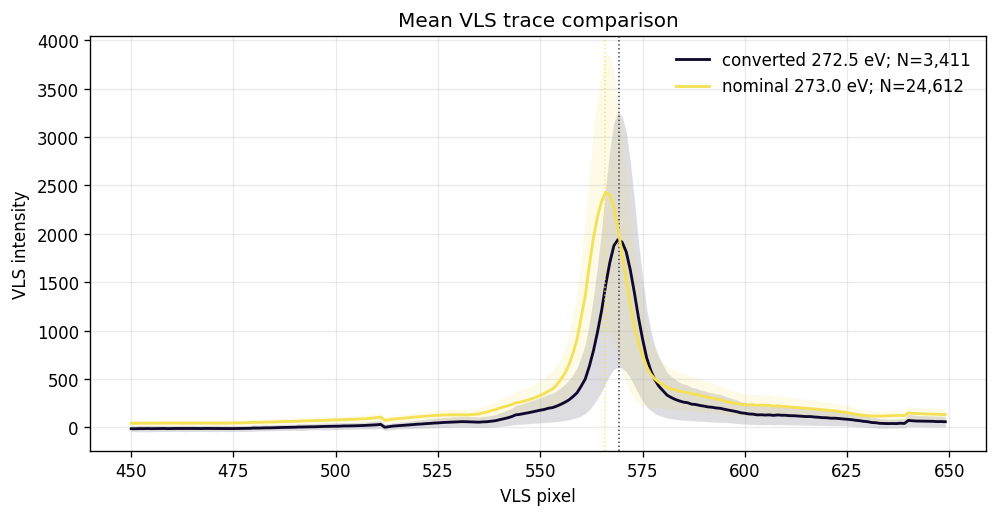

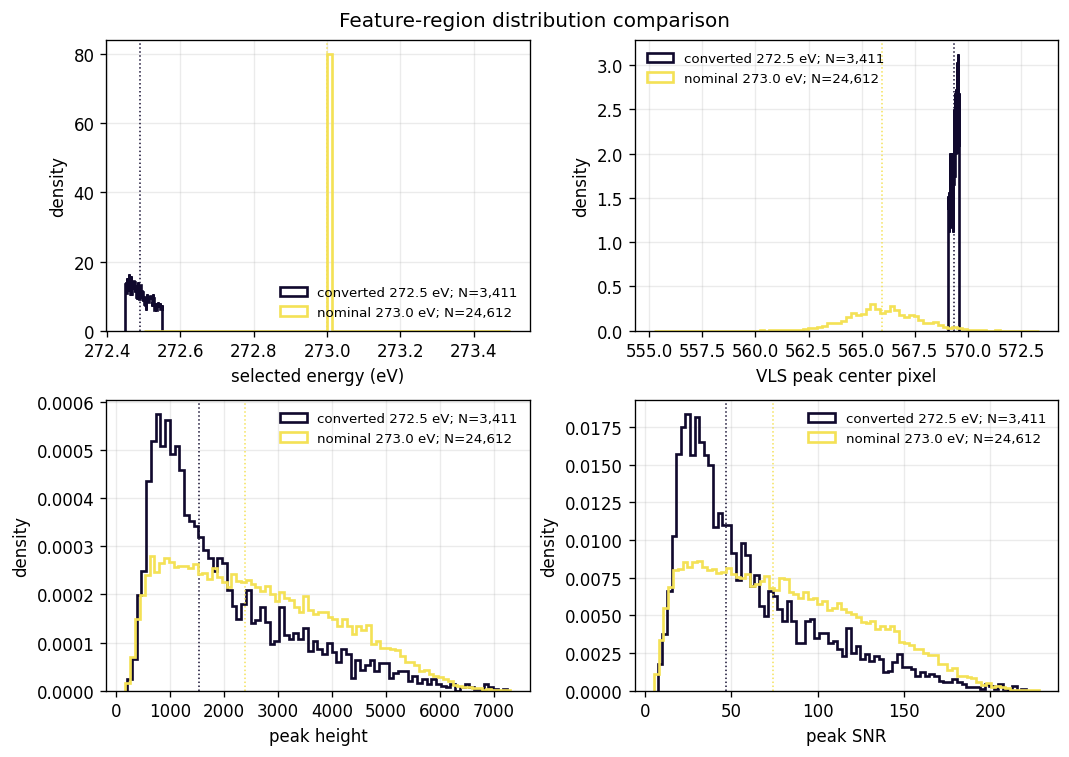

In [21]:
fig, ax = gx.plot_feature_vls_mean_comparison(features, labels=feature_labels)
plt.show()

fig, axes = gx.plot_feature_distribution_comparison(features, labels=feature_labels, bins=FEATURE_HIST_BINS)
plt.show()


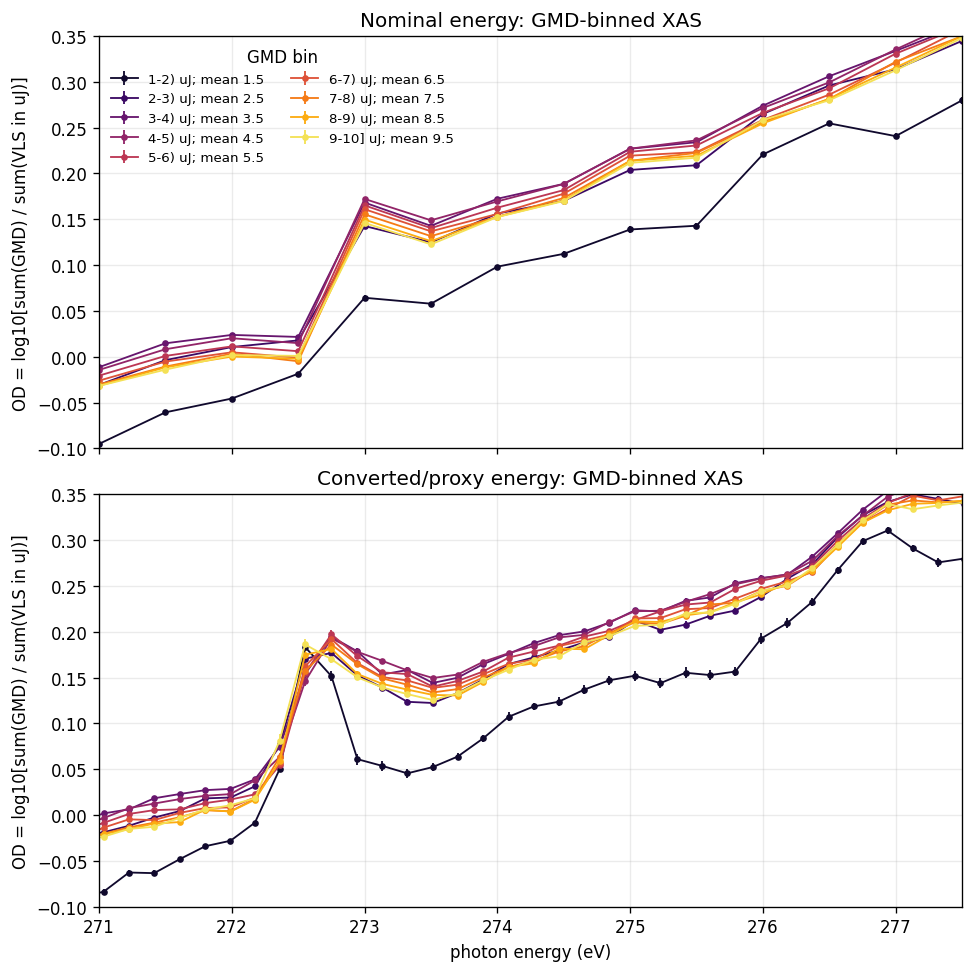

In [22]:
# XAS-only nominal/converted plot
XAS_ONLY_XLIM = (271, 277.5)
NOMINAL_XAS_ONLY_YLIM = (-0.1, 0.35)
CONVERTED_XAS_ONLY_YLIM = (-0.1, 0.35)
XAS_ONLY_SHOW_ERRORBARS = True

fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharex=True, constrained_layout=True)
colors = plt.cm.inferno(np.linspace(0.08, 0.92, len(result.gmd_labels)))

panels = [
    (
        axes[0],
        result.nominal,
        bootstrap.nominal_od_sigma,
        "Nominal energy: GMD-binned XAS",
        NOMINAL_XAS_ONLY_YLIM,
    ),
    (
        axes[1],
        result.converted,
        bootstrap.converted_od_sigma,
        "Converted/proxy energy: GMD-binned XAS",
        CONVERTED_XAS_ONLY_YLIM,
    ),
]

for ax, binned, od_sigma, title, ylim in panels:
    order = gx.finite_x_order(binned.x)
    x = binned.x[order]
    od = binned.od[order]
    err = od_sigma[order]
    for ig, (label, color) in enumerate(zip(result.gmd_labels, colors)):
        keep = np.isfinite(x) & np.isfinite(od[:, ig])
        if not np.any(keep):
            continue
        if XAS_ONLY_SHOW_ERRORBARS:
            ax.errorbar(x[keep], od[keep, ig], yerr=err[keep, ig], marker="o", ms=3, lw=1.1, color=color, label=label)
        else:
            ax.plot(x[keep], od[keep, ig], marker="o", ms=3, lw=1.1, color=color, label=label)
    ax.set_title(title)
    ax.set_ylabel("OD = log10[sum(GMD) / sum(VLS in uJ)]")
    ax.grid(alpha=0.25)
    if ylim is not None:
        ax.set_ylim(*ylim)

axes[0].legend(title="GMD bin", frameon=False, fontsize=8, ncol=2)
axes[1].set_xlabel("photon energy (eV)")
if XAS_ONLY_XLIM is not None:
    axes[1].set_xlim(*XAS_ONLY_XLIM)
plt.show()
